# **CONECTARNOS AL DRIVE**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **INSTALAMOS LIBRERIAS NECESARIAS**

In [2]:
!pip install ydata-profiling

# **IMPORTAR LIBRERÍAS NECESARIAS**

In [3]:
import pandas as pd
from ydata_profiling import ProfileReport
import numpy as np

from sklearn.preprocessing import LabelEncoder

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTEENN
from imblearn.combine import SMOTETomek

from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from imblearn.pipeline import Pipeline

from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
import matplotlib.pyplot as plt

import pickle

# **CONVERTIR LAS TABLAS A DATAFRAMES**

In [4]:
# DICIEMBRE
df_clientes_diciembre = pd.read_csv(r'/content/drive/MyDrive/Machine Learning/3. José Ángel Carballo/2.ejercicio_churn/diciembre/clientes_diciembre.csv', sep='|')
df_consumos_diciembre = pd.read_csv(r'/content/drive/MyDrive/Machine Learning/3. José Ángel Carballo/2.ejercicio_churn/diciembre/consumos_diciembre.csv', sep='|')
df_financiacion_diciembre = pd.read_csv(r'/content/drive/MyDrive/Machine Learning/3. José Ángel Carballo/2.ejercicio_churn/diciembre/financiacion_diciembre.csv', sep='|')
df_productos_diciembre = pd.read_csv(r'/content/drive/MyDrive/Machine Learning/3. José Ángel Carballo/2.ejercicio_churn/diciembre/productos_diciembre.csv', sep='|')

# ENERO
df_clientes_enero = pd.read_csv(r'/content/drive/MyDrive/Machine Learning/3. José Ángel Carballo/2.ejercicio_churn/enero/clientes_enero.csv', sep='|')
df_consumos_enero = pd.read_csv(r'/content/drive/MyDrive/Machine Learning/3. José Ángel Carballo/2.ejercicio_churn/enero/consumos_enero.csv', sep='|')
df_financiacion_enero = pd.read_csv(r'/content/drive/MyDrive/Machine Learning/3. José Ángel Carballo/2.ejercicio_churn/enero/financiacion_enero.csv', sep='|')
df_productos_enero = pd.read_csv(r'/content/drive/MyDrive/Machine Learning/3. José Ángel Carballo/2.ejercicio_churn/enero/productos_enero.csv', sep='|')

# **VER DIMENSIONES DE LOS DF**

In [5]:
# DICIEMBRE
print('--DIMENSIONES DICIEMBRE--')
print(df_clientes_diciembre.shape)
print(df_consumos_diciembre.shape)
print(df_financiacion_diciembre.shape)
print(df_productos_diciembre.shape)

# ENERO
print('\n--DIMENSIONES ENERO--')
print(df_clientes_enero.shape)
print(df_consumos_enero.shape)
print(df_financiacion_enero.shape)
print(df_productos_enero.shape)

--DIMENSIONES DICIEMBRE--
(95467, 8)
(95467, 6)
(24198, 4)
(95467, 4)

--DIMENSIONES ENERO--
(92710, 8)
(92711, 6)
(25332, 4)
(92711, 4)


# **LIMPIEZA DE DATOS**

DICIEMBRE

In [6]:
# ¿Hay duplicados?
print(df_clientes_diciembre.duplicated().value_counts())
print(df_consumos_diciembre.duplicated().value_counts())
print(df_financiacion_diciembre.duplicated().value_counts())
print(df_productos_diciembre.duplicated().value_counts())

False    95466
True         1
Name: count, dtype: int64
False    95467
Name: count, dtype: int64
False    24198
Name: count, dtype: int64
False    95467
Name: count, dtype: int64


In [7]:
# ¿Cuál es el duplicado?
df_clientes_diciembre[df_clientes_diciembre.duplicated()]

,id,edad,facturacion,antiguedad,provincia,num_lineas,num_dt,incidencia
95460,99993,58,375.65842,2016-06-09 21:39:00,Santa Cruz de Tenerife,5,NaN,NaN


In [8]:
# Comprobamos el duplicado
df_clientes_diciembre[df_clientes_diciembre['id']==99993]

,id,edad,facturacion,antiguedad,provincia,num_lineas,num_dt,incidencia
95459,99993,58,375.65842,2016-06-09 21:39:00,Santa Cruz de Tenerife,5,NaN,NaN
95460,99993,58,375.65842,2016-06-09 21:39:00,Santa Cruz de Tenerife,5,NaN,NaN


In [9]:
#Eliminamos el duplicado
df_clientes_diciembre.drop(95460, axis=0, inplace=True)

ENERO

In [10]:
# ¿Hay duplicados?
print(df_clientes_enero.duplicated().value_counts())
print(df_consumos_enero.duplicated().value_counts())
print(df_financiacion_enero.duplicated().value_counts())
print(df_productos_enero.duplicated().value_counts())

False    92710
Name: count, dtype: int64
False    92711
Name: count, dtype: int64
False    25332
Name: count, dtype: int64
False    92711
Name: count, dtype: int64


# **UNIR TABLAS**

In [11]:
# ¿Están contenidos todos los ids en todas las tablas?
# DICIEMBRE
print(df_clientes_diciembre['id'].isin(df_consumos_diciembre['id']).value_counts())
print(df_clientes_diciembre['id'].isin(df_productos_diciembre['id']).value_counts())
print(df_clientes_diciembre['id'].isin(df_financiacion_diciembre['id']).value_counts())

# ENERO
print(df_clientes_enero['id'].isin(df_consumos_enero['id']).value_counts())
print(df_clientes_enero['id'].isin(df_productos_enero['id']).value_counts())
print(df_clientes_enero['id'].isin(df_financiacion_enero['id']).value_counts())

id
True    95466
Name: count, dtype: int64
id
True    95466
Name: count, dtype: int64
id
False    71269
True     24197
Name: count, dtype: int64
id
True    92710
Name: count, dtype: int64
id
True    92710
Name: count, dtype: int64
id
False    67378
True     25332
Name: count, dtype: int64


DICIEMBRE

In [12]:
# Visualizar la tabla de clientes
df_clientes_diciembre

,id,edad,facturacion,antiguedad,provincia,num_lineas,num_dt,incidencia
0,1,63,216.028109,2018-11-23 08:48:00,La Rioja,5,NaN,NaN
1,2,84,255.830842,2017-08-22 03:19:00,Vizcaya,3,NaN,NaN
2,3,66,135.768153,2001-12-27 13:50:00,Albacete,4,NaN,NaN
3,4,69,255.658527,2015-08-08 10:53:00,Lugo,4,NaN,NaN
4,5,30,22.302845,1997-08-29 02:19:00,Tarragona,2,2.0,NaN
...,...,...,...,...,...,...,...,...
95462,99995,65,173.741667,2019-03-05 00:00:00,Murcia,5,NaN,NaN
95463,99996,36,215.890326,2013-04-09 13:33:00,Guadalajara,3,NaN,NaN
95464,99997,68,285.890750,2003-08-08 23:57:00,Asturias,5,NaN,NaN
95465,99998,20,383.167610,2013-03-27 20:07:00,Álava,4,NaN,NaN


In [13]:
# Unir la tabla de clientes con la de productos
df_diciembre = pd.merge(df_clientes_diciembre, df_productos_diciembre, on='id', how='left')

# Visualizar la nueva tabla
df_diciembre

,id,edad,facturacion,antiguedad,provincia,num_lineas,num_dt,incidencia,conexion,vel_conexion,TV
0,1,63,216.028109,2018-11-23 08:48:00,La Rioja,5,NaN,NaN,FIBRA,50MB,tv-futbol
1,2,84,255.830842,2017-08-22 03:19:00,Vizcaya,3,NaN,NaN,FIBRA,600MB,tv-futbol
2,3,66,135.768153,2001-12-27 13:50:00,Albacete,4,NaN,NaN,ADSL,35MB,tv-futbol
3,4,69,255.658527,2015-08-08 10:53:00,Lugo,4,NaN,NaN,FIBRA,200MB,tv-familiar
4,5,30,22.302845,1997-08-29 02:19:00,Tarragona,2,2.0,NaN,ADSL,10MB,tv-futbol
...,...,...,...,...,...,...,...,...,...,...,...
95461,99995,65,173.741667,2019-03-05 00:00:00,Murcia,5,NaN,NaN,ADSL,35MB,tv-familiar
95462,99996,36,215.890326,2013-04-09 13:33:00,Guadalajara,3,NaN,NaN,ADSL,30MB,tv-futbol
95463,99997,68,285.890750,2003-08-08 23:57:00,Asturias,5,NaN,NaN,FIBRA,200MB,tv-futbol
95464,99998,20,383.167610,2013-03-27 20:07:00,Álava,4,NaN,NaN,ADSL,20MB,tv-futbol


In [14]:
# Unir la nueva tabla con la de consumos
df_diciembre = pd.merge(df_diciembre, df_consumos_diciembre, on='id', how='left')

# Visualizar la nueva tabla
df_diciembre

,id,edad,facturacion,antiguedad,provincia,num_lineas,num_dt,incidencia,conexion,vel_conexion,TV,num_llamad_ent,num_llamad_sal,mb_datos,seg_llamad_ent,seg_llamad_sal
0,1,63,216.028109,2018-11-23 08:48:00,La Rioja,5,NaN,NaN,FIBRA,50MB,tv-futbol,110,79,10897,12806,13751
1,2,84,255.830842,2017-08-22 03:19:00,Vizcaya,3,NaN,NaN,FIBRA,600MB,tv-futbol,189,89,18657,6499,10862
2,3,66,135.768153,2001-12-27 13:50:00,Albacete,4,NaN,NaN,ADSL,35MB,tv-futbol,129,30,15511,17013,16743
3,4,69,255.658527,2015-08-08 10:53:00,Lugo,4,NaN,NaN,FIBRA,200MB,tv-familiar,51,52,12670,3393,6771
4,5,30,22.302845,1997-08-29 02:19:00,Tarragona,2,2.0,NaN,ADSL,10MB,tv-futbol,183,3,23756,18436,4485
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95461,99995,65,173.741667,2019-03-05 00:00:00,Murcia,5,NaN,NaN,ADSL,35MB,tv-familiar,121,98,13403,6197,6853
95462,99996,36,215.890326,2013-04-09 13:33:00,Guadalajara,3,NaN,NaN,ADSL,30MB,tv-futbol,98,13,5291,3684,1667
95463,99997,68,285.890750,2003-08-08 23:57:00,Asturias,5,NaN,NaN,FIBRA,200MB,tv-futbol,226,20,20002,572,5679
95464,99998,20,383.167610,2013-03-27 20:07:00,Álava,4,NaN,NaN,ADSL,20MB,tv-futbol,126,26,16448,833,14398


In [15]:
# Unir la nueva tabla con la de financiación (OJO QUE ESTA TABLA TIENE MUCHOS NaNs, pero sabemos el valor de estos NaNs).
# Viualizamos la tabla de financiación
df_financiacion_diciembre

,id,financiacion,imp_financ,descuentos
0,2,NaN,NaN,SI
1,3,NaN,NaN,SI
2,7,SI,31.553269,NaN
3,11,NaN,NaN,SI
4,12,NaN,NaN,SI
...,...,...,...,...
24193,99990,SI,28.355596,NaN
24194,99994,NaN,NaN,SI
24195,99995,SI,23.138779,NaN
24196,99997,SI,14.616422,NaN


In [16]:
# Unir la nueva tabla con la de financiación (OJO QUE ESTA TABLA TIENE MUCHOS NaNs, pero lo hacemos porque sabemos el valor de estos NaNs)
df_diciembre = pd.merge(df_diciembre,df_financiacion_diciembre, on='id', how='left' )

# Visualizar la nueva tabla
df_diciembre

,id,edad,facturacion,antiguedad,provincia,num_lineas,num_dt,incidencia,conexion,vel_conexion,TV,num_llamad_ent,num_llamad_sal,mb_datos,seg_llamad_ent,seg_llamad_sal,financiacion,imp_financ,descuentos
0,1,63,216.028109,2018-11-23 08:48:00,La Rioja,5,NaN,NaN,FIBRA,50MB,tv-futbol,110,79,10897,12806,13751,NaN,NaN,NaN
1,2,84,255.830842,2017-08-22 03:19:00,Vizcaya,3,NaN,NaN,FIBRA,600MB,tv-futbol,189,89,18657,6499,10862,NaN,NaN,SI
2,3,66,135.768153,2001-12-27 13:50:00,Albacete,4,NaN,NaN,ADSL,35MB,tv-futbol,129,30,15511,17013,16743,NaN,NaN,SI
3,4,69,255.658527,2015-08-08 10:53:00,Lugo,4,NaN,NaN,FIBRA,200MB,tv-familiar,51,52,12670,3393,6771,NaN,NaN,NaN
4,5,30,22.302845,1997-08-29 02:19:00,Tarragona,2,2.0,NaN,ADSL,10MB,tv-futbol,183,3,23756,18436,4485,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95461,99995,65,173.741667,2019-03-05 00:00:00,Murcia,5,NaN,NaN,ADSL,35MB,tv-familiar,121,98,13403,6197,6853,SI,23.138779,NaN
95462,99996,36,215.890326,2013-04-09 13:33:00,Guadalajara,3,NaN,NaN,ADSL,30MB,tv-futbol,98,13,5291,3684,1667,NaN,NaN,NaN
95463,99997,68,285.890750,2003-08-08 23:57:00,Asturias,5,NaN,NaN,FIBRA,200MB,tv-futbol,226,20,20002,572,5679,SI,14.616422,NaN
95464,99998,20,383.167610,2013-03-27 20:07:00,Álava,4,NaN,NaN,ADSL,20MB,tv-futbol,126,26,16448,833,14398,NaN,NaN,NaN


ENERO

In [17]:
# Visualizar la tabla de clientes
df_clientes_enero

,id,edad,facturacion,antiguedad,provincia,num_lineas,num_dt,incidencia
0,1,63,216.028109,11/23/2018 08:48 AM,La Rioja,5,NaN,NaN
1,2,84,255.830842,08/22/2017 03:19 AM,Vizcaya,3,NaN,NaN
2,3,66,135.768153,12/27/2001 01:50 PM,Albacete,4,NaN,NaN
3,4,69,255.658527,08/08/2015 10:53 AM,Lugo,4,NaN,NaN
4,6,51,99.348645,11/04/1997 11:43 AM,Huelva,4,NaN,NaN
...,...,...,...,...,...,...,...,...
92705,99996,36,215.890326,04/09/2013 01:33 PM,Guadalajara,3,NaN,NaN
92706,99997,68,285.890750,08/08/2003 11:57 PM,Asturias,5,NaN,NaN
92707,99998,20,383.167610,03/27/2013 08:07 PM,Álava,4,NaN,NaN
92708,99999,53,53.301395,01/18/2020 02:30 AM,Sevilla,2,NaN,NaN


In [18]:
# Unir la tabla de clientes con la de productos
df_enero = pd.merge(df_clientes_enero, df_productos_enero, on='id', how='left')

# Visualizar la nueva tabla
df_enero

,id,edad,facturacion,antiguedad,provincia,num_lineas,num_dt,incidencia,conexion,vel_conexion,TV
0,1,63,216.028109,11/23/2018 08:48 AM,La Rioja,5,NaN,NaN,FIBRA,50MB,tv-futbol
1,2,84,255.830842,08/22/2017 03:19 AM,Vizcaya,3,NaN,NaN,FIBRA,600MB,tv-futbol
2,3,66,135.768153,12/27/2001 01:50 PM,Albacete,4,NaN,NaN,ADSL,35MB,tv-futbol
3,4,69,255.658527,08/08/2015 10:53 AM,Lugo,4,NaN,NaN,FIBRA,200MB,tv-familiar
4,6,51,99.348645,11/04/1997 11:43 AM,Huelva,4,NaN,NaN,FIBRA,200MB,tv-futbol
...,...,...,...,...,...,...,...,...,...,...,...
92705,99996,36,215.890326,04/09/2013 01:33 PM,Guadalajara,3,NaN,NaN,ADSL,30MB,tv-futbol
92706,99997,68,285.890750,08/08/2003 11:57 PM,Asturias,5,NaN,NaN,FIBRA,200MB,tv-futbol
92707,99998,20,383.167610,03/27/2013 08:07 PM,Álava,4,NaN,NaN,ADSL,20MB,tv-futbol
92708,99999,53,53.301395,01/18/2020 02:30 AM,Sevilla,2,NaN,NaN,FIBRA,50MB,tv-futbol


In [19]:
# Unir la nueva tabla con la de consumos
df_enero = pd.merge(df_enero, df_consumos_enero, on='id', how='left')

# Visualizar la nueva tabla
df_enero

,id,edad,facturacion,antiguedad,provincia,num_lineas,num_dt,incidencia,conexion,vel_conexion,TV,num_llamad_ent,num_llamad_sal,mb_datos,seg_llamad_ent,seg_llamad_sal
0,1,63,216.028109,11/23/2018 08:48 AM,La Rioja,5,NaN,NaN,FIBRA,50MB,tv-futbol,95,19,6525,7634,18520
1,2,84,255.830842,08/22/2017 03:19 AM,Vizcaya,3,NaN,NaN,FIBRA,600MB,tv-futbol,44,36,14471,14541,8016
2,3,66,135.768153,12/27/2001 01:50 PM,Albacete,4,NaN,NaN,ADSL,35MB,tv-futbol,94,27,1428,5248,7106
3,4,69,255.658527,08/08/2015 10:53 AM,Lugo,4,NaN,NaN,FIBRA,200MB,tv-familiar,186,20,20083,7372,5052
4,6,51,99.348645,11/04/1997 11:43 AM,Huelva,4,NaN,NaN,FIBRA,200MB,tv-futbol,37,32,19078,5009,8686
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
92705,99996,36,215.890326,04/09/2013 01:33 PM,Guadalajara,3,NaN,NaN,ADSL,30MB,tv-futbol,217,96,9059,7735,8823
92706,99997,68,285.890750,08/08/2003 11:57 PM,Asturias,5,NaN,NaN,FIBRA,200MB,tv-futbol,168,99,9303,4798,3996
92707,99998,20,383.167610,03/27/2013 08:07 PM,Álava,4,NaN,NaN,ADSL,20MB,tv-futbol,188,71,19018,1237,16720
92708,99999,53,53.301395,01/18/2020 02:30 AM,Sevilla,2,NaN,NaN,FIBRA,50MB,tv-futbol,138,40,20264,10552,17637


In [20]:
# Unir la nueva tabla con la de financiación (OJO QUE ESTA TABLA TIENE MUCHOS NaNs, pero lo hacemos porque sabemos el valor de estos NaNs)
df_enero = pd.merge(df_enero,df_financiacion_enero, on='id', how='left' )

# Visualizar la nueva tabla
df_enero

,id,edad,facturacion,antiguedad,provincia,num_lineas,num_dt,incidencia,conexion,vel_conexion,TV,num_llamad_ent,num_llamad_sal,mb_datos,seg_llamad_ent,seg_llamad_sal,financiacion,imp_financ,descuentos
0,1,63,216.028109,11/23/2018 08:48 AM,La Rioja,5,NaN,NaN,FIBRA,50MB,tv-futbol,95,19,6525,7634,18520,NaN,NaN,NaN
1,2,84,255.830842,08/22/2017 03:19 AM,Vizcaya,3,NaN,NaN,FIBRA,600MB,tv-futbol,44,36,14471,14541,8016,NaN,NaN,SI
2,3,66,135.768153,12/27/2001 01:50 PM,Albacete,4,NaN,NaN,ADSL,35MB,tv-futbol,94,27,1428,5248,7106,NaN,NaN,SI
3,4,69,255.658527,08/08/2015 10:53 AM,Lugo,4,NaN,NaN,FIBRA,200MB,tv-familiar,186,20,20083,7372,5052,NaN,NaN,NaN
4,6,51,99.348645,11/04/1997 11:43 AM,Huelva,4,NaN,NaN,FIBRA,200MB,tv-futbol,37,32,19078,5009,8686,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
92705,99996,36,215.890326,04/09/2013 01:33 PM,Guadalajara,3,NaN,NaN,ADSL,30MB,tv-futbol,217,96,9059,7735,8823,NaN,NaN,NaN
92706,99997,68,285.890750,08/08/2003 11:57 PM,Asturias,5,NaN,NaN,FIBRA,200MB,tv-futbol,168,99,9303,4798,3996,SI,14.616422,NaN
92707,99998,20,383.167610,03/27/2013 08:07 PM,Álava,4,NaN,NaN,ADSL,20MB,tv-futbol,188,71,19018,1237,16720,NaN,NaN,NaN
92708,99999,53,53.301395,01/18/2020 02:30 AM,Sevilla,2,NaN,NaN,FIBRA,50MB,tv-futbol,138,40,20264,10552,17637,NaN,NaN,NaN


# **CREACIÓN DE LA VARIABLE TARGET**

In [21]:
# No tenemos la target, pero podemos calcularla. ¿cúantos clientes de diciembre no siguen en enero?
target = df_diciembre['id'].isin(df_enero['id']).replace({True: 0, False: 1})

/tmp/ipykernel_37544/533908003.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  target = df_diciembre['id'].isin(df_enero['id']).replace({True: 0, False: 1})


In [22]:
target.value_counts()

,count
id,
0,88380
1,7086


# **EDA (ANÁLISIS EXPLORATORIO DE DATOS)**

In [23]:
df_diciembre.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 95466 entries, 0 to 95465
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              95466 non-null  int64  
 1   edad            95466 non-null  int64  
 2   facturacion     95466 non-null  float64
 3   antiguedad      95466 non-null  object 
 4   provincia       95466 non-null  object 
 5   num_lineas      95466 non-null  int64  
 6   num_dt          4728 non-null   float64
 7   incidencia      3574 non-null   object 
 8   conexion        95466 non-null  object 
 9   vel_conexion    95463 non-null  object 
 10  TV              95466 non-null  object 
 11  num_llamad_ent  95466 non-null  int64  
 12  num_llamad_sal  95466 non-null  int64  
 13  mb_datos        95466 non-null  int64  
 14  seg_llamad_ent  95466 non-null  int64  
 15  seg_llamad_sal  95466 non-null  int64  
 16  financiacion    6371 non-null   object 
 17  imp_financ      6371 non-null  

In [24]:
df_diciembre.describe()

,id,edad,facturacion,num_lineas,num_dt,num_llamad_ent,num_llamad_sal,mb_datos,seg_llamad_ent,seg_llamad_sal,imp_financ
count,95466.000000,95466.000000,95466.000000,95466.000000,4728.000000,95466.000000,95466.000000,95466.00000,95466.000000,95466.000000,6371.000000
mean,49993.790250,49.779429,207.391736,3.559267,2.508249,124.816448,50.022762,12489.85223,9945.119268,9929.639128,22.268666
std,28872.800179,19.833061,111.343481,1.095546,1.122088,72.492280,29.120056,7239.43826,5784.179502,5819.190015,10.178457
min,1.000000,18.000000,15.000439,1.000000,1.000000,0.000000,0.000000,0.00000,0.000000,0.000000,5.009999
25%,24997.250000,32.000000,111.382675,3.000000,2.000000,62.000000,25.000000,6177.25000,4951.000000,4910.000000,13.432211
50%,49969.500000,49.000000,206.808284,4.000000,3.000000,124.000000,50.000000,12466.00000,9922.500000,9922.000000,21.883685
75%,75020.750000,67.000000,304.429406,4.000000,4.000000,188.000000,75.000000,18785.75000,14948.750000,14961.000000,31.155565
max,100000.000000,85.000000,399.998433,39.000000,4.000000,250.000000,100.000000,25000.00000,20000.000000,20000.000000,39.990128


In [25]:
# Visualización de datos de manera automática
profile = ProfileReport(df_diciembre, title="Profiling Report")
profile

Output hidden; open in https://colab.research.google.com to view.

# **PRE-PROCESADO**

Variable "antigüedad"

In [26]:
# Vemos la variable
df_diciembre['antiguedad']

,antiguedad
0,2018-11-23 08:48:00
1,2017-08-22 03:19:00
2,2001-12-27 13:50:00
3,2015-08-08 10:53:00
4,1997-08-29 02:19:00
...,...
95461,2019-03-05 00:00:00
95462,2013-04-09 13:33:00
95463,2003-08-08 23:57:00
95464,2013-03-27 20:07:00


In [27]:
# Es de formato texto (object), así que hay que convertirlo en formato datetime y calcular antiguedad real
# DICIEMBRE
df_diciembre['antiguedad'] = (pd.to_datetime('2019-12-31') - pd.to_datetime(df_diciembre['antiguedad'])).dt.days

# ENERO
df_enero['antiguedad'] = (pd.to_datetime('2020-01-31') - pd.to_datetime(df_enero['antiguedad'])).dt.days

Variable "provincia"

In [28]:
df_diciembre['provincia'].value_counts()

,count
provincia,
Zaragoza,1991
Navarra,1986
Málaga,1973
Valencia,1972
Asturias,1972
Murcia,1967
Orense,1958
Alicante,1954
Córdoba,1949


In [29]:
# Generar dummies no tiene sentido porque creamos demasiadas variables;
# Podríamos categorizarla y estaría bien: df_diciembre['provincia'].astype('category');
# Pero vamos a AGRUPAR: por valores raros no, porque la distribución es prácticamente igual,
# Vamos a agrupar por CCAA ya que conocemos el contexto

In [30]:
# Al estar en Colab hay que hacer esto con el web scraping:
import requests

headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36'}

response = requests.get('https://es.wikipedia.org/wiki/Provincia_(Espa%C3%B1a)', headers=headers)

# Elegimos cual es la columna de la web que queremos [2]
df_ccaa = pd.read_html(response.text)[2][['Provincia', 'Comunidad autónoma']]

# Hacemos rename de ccaa para que sea más cómodo y de Provincia, ya que en el dataset original está con minúsculas
df_ccaa.rename(columns={'Comunidad autónoma': 'ccaa', 'Provincia': 'provincia'}, inplace=True)

# Sustituimos el nombre de Baleares por Islas Baleares
df_ccaa['provincia'] =  df_ccaa['provincia'].replace({'Baleares': 'Islas Baleares'})

# Vemos cómo queda
df_ccaa

/tmp/ipykernel_37544/511746847.py:10: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  df_ccaa = pd.read_html(response.text)[2][['Provincia', 'Comunidad autónoma']]


,provincia,ccaa
0,Álava,País Vasco
1,Albacete,Castilla-La Mancha
2,Alicante,Comunidad Valenciana
3,Almería,Andalucía
4,Asturias,Principado de Asturias
5,Ávila,Castilla y León
6,Badajoz,Extremadura
7,Barcelona,Cataluña
8,Burgos,Castilla y León
9,Cáceres,Extremadura


In [31]:
# Mergeamos las dos tablas
df_diciembre = pd.merge(df_diciembre, df_ccaa, on='provincia', how='left' )

In [32]:
# Con el .map(...) buscamos cada nombre de CCAA en tu columna original y lo reemplazmos por su frecuencia numérica
df_diciembre['ccaa'] = df_diciembre['ccaa'].map(df_diciembre['ccaa'].value_counts())

In [33]:
# Hacemos el método LabelEncoder, pero como última opción
le = LabelEncoder()
df_diciembre['provincia'] = le.fit_transform(df_diciembre['provincia'])
print(le.classes_)

['Albacete' 'Alicante' 'Almería' 'Asturias' 'Badajoz' 'Barcelona' 'Burgos'
 'Cantabria' 'Castellón' 'Ciudad Real' 'Cuenca' 'Cáceres' 'Cádiz'
 'Córdoba' 'Gerona' 'Granada' 'Guadalajara' 'Guipúzcoa' 'Huelva' 'Huesca'
 'Islas Baleares' 'Jaén' 'La Coruña' 'La Rioja' 'Las Palmas' 'León' 'Lugo'
 'Lérida' 'Madrid' 'Murcia' 'Málaga' 'Navarra' 'Orense' 'Palencia'
 'Pontevedra' 'Salamanca' 'Santa Cruz de Tenerife' 'Segovia' 'Sevilla'
 'Soria' 'Tarragona' 'Teruel' 'Toledo' 'Valencia' 'Valladolid' 'Vizcaya'
 'Zamora' 'Zaragoza' 'Álava' 'Ávila']


In [34]:
# Comprobamos el dataframe para ver qué podemos hacer a continuación
df_diciembre.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 95466 entries, 0 to 95465
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              95466 non-null  int64  
 1   edad            95466 non-null  int64  
 2   facturacion     95466 non-null  float64
 3   antiguedad      95466 non-null  int64  
 4   provincia       95466 non-null  int64  
 5   num_lineas      95466 non-null  int64  
 6   num_dt          4728 non-null   float64
 7   incidencia      3574 non-null   object 
 8   conexion        95466 non-null  object 
 9   vel_conexion    95463 non-null  object 
 10  TV              95466 non-null  object 
 11  num_llamad_ent  95466 non-null  int64  
 12  num_llamad_sal  95466 non-null  int64  
 13  mb_datos        95466 non-null  int64  
 14  seg_llamad_ent  95466 non-null  int64  
 15  seg_llamad_sal  95466 non-null  int64  
 16  financiacion    6371 non-null   object 
 17  imp_financ      6371 non-null  

Rellenar los valores nulos

In [35]:
df_diciembre.isnull().sum()

,0
id,0
edad,0
facturacion,0
antiguedad,0
provincia,0
num_lineas,0
num_dt,90738
incidencia,91892
conexion,0
vel_conexion,3


In [36]:
######### RELLENAR 'num_dt'
df_diciembre['num_dt'].value_counts()

,count
num_dt,
4.0,1206
1.0,1179
2.0,1173
3.0,1170


In [37]:
# Sabemos que los nulos de esta columna son 0
lista_cero = ['imp_financ', 'num_dt']

# Reemplazamos nulos por 0
for i in lista_cero:
    df_diciembre[i].fillna(0, inplace=True)

/tmp/ipykernel_37544/1409224124.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_diciembre[i].fillna(0, inplace=True)


In [38]:
# Sabemos que los nulos de esta columna son NO
lista_no = ['financiacion', 'descuentos' ,'incidencia']

# Reemplazamos nulos por NO
for i in lista_no:
    df_diciembre[i].fillna('NO', inplace=True)

/tmp/ipykernel_37544/1650860544.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_diciembre[i].fillna('NO', inplace=True)


In [39]:
######### RELLENAR 'vel_conexion'

In [40]:
# Vemos cuántos eran los nulos
df_diciembre['vel_conexion'].isnull().value_counts()

,count
vel_conexion,
False,95463
True,3


In [41]:
# Vemos cuáles son nulos
df_diciembre[df_diciembre['vel_conexion'].isnull()]

,id,edad,facturacion,antiguedad,provincia,num_lineas,num_dt,incidencia,conexion,vel_conexion,TV,num_llamad_ent,num_llamad_sal,mb_datos,seg_llamad_ent,seg_llamad_sal,financiacion,imp_financ,descuentos,ccaa
56983,59665,64,258.698493,3898,33,3,0.0,NO,FIBRA,NaN,tv-familiar,192,30,938,16230,8443,NO,0.0,NO,17111
56984,59666,77,258.276588,2180,8,3,0.0,NO,ADSL,NaN,tv-familiar,234,1,14798,11515,13342,NO,0.0,NO,5841
56985,59667,20,295.106696,2381,39,3,0.0,NO,FIBRA,NaN,tv-futbol,28,94,15396,12113,5958,NO,0.0,SI,17111


In [42]:
# Vemos también si hay algún valor extraño en 'vel_conexion' y nos damos cuenta de que hay otros 3
df_diciembre['vel_conexion'].value_counts()

,count
vel_conexion,
200MB,9675
600MB,9622
50MB,9474
300MB,9460
100MB,9331
20MB,8113
25MB,8112
10MB,7969
30MB,7948


In [43]:
# Gracias al EDA nos hemos dado cuenta que 'vel_conexion' está correlada con 'conexion', así que vamos a ver qué conexión tienen estos 'vel_conexion'extraños
df_diciembre[df_diciembre['vel_conexion'] == '16598']

,id,edad,facturacion,antiguedad,provincia,num_lineas,num_dt,incidencia,conexion,vel_conexion,TV,num_llamad_ent,num_llamad_sal,mb_datos,seg_llamad_ent,seg_llamad_sal,financiacion,imp_financ,descuentos,ccaa
12,13,55,209.36555,137,18,3,0.0,NO,FIBRA,16598,tv-familiar,118,13,18030,16766,13801,NO,0.0,NO,15390


In [44]:
# Gracias al EDA nos hemos dado cuenta que 'vel_conexion' está correlada con 'conexion', así que vamos a ver qué conexión tienen estos 'vel_conexion'extraños
df_diciembre[df_diciembre['vel_conexion'] == '1']

,id,edad,facturacion,antiguedad,provincia,num_lineas,num_dt,incidencia,conexion,vel_conexion,TV,num_llamad_ent,num_llamad_sal,mb_datos,seg_llamad_ent,seg_llamad_sal,financiacion,imp_financ,descuentos,ccaa
70426,73779,26,209.565464,7422,34,5,1.0,NO,ADSL,1,tv-futbol,82,29,9667,7184,2677,NO,0.0,NO,7657


In [45]:
# Gracias al EDA nos hemos dado cuenta que 'vel_conexion' está correlada con 'conexion', así que vamos a ver qué conexión tienen estos 'vel_conexion'extraños
df_diciembre[df_diciembre['vel_conexion'] == '?']

,id,edad,facturacion,antiguedad,provincia,num_lineas,num_dt,incidencia,conexion,vel_conexion,TV,num_llamad_ent,num_llamad_sal,mb_datos,seg_llamad_ent,seg_llamad_sal,financiacion,imp_financ,descuentos,ccaa
70528,73889,69,118.515385,6108,8,2,0.0,NO,FIBRA,?,tv-familiar,74,99,12169,19080,2068,NO,0.0,NO,5841


In [46]:
# Convertimos los valores extraños a NaNs
df_diciembre.iloc[12] = df_diciembre.iloc[12].replace({'16598':np.nan})
df_diciembre.iloc[70426] = df_diciembre.iloc[70426].replace({'1':np.nan})
df_diciembre.iloc[70528] = df_diciembre.iloc[70528].replace({'?':np.nan})

In [47]:
# Comprobamos que ahora hay 6 NaNs en vez de 3
df_diciembre['vel_conexion'].isnull().sum()

np.int64(6)

In [48]:
# Los visualizamos
df_diciembre[df_diciembre['vel_conexion'].isnull()]

,id,edad,facturacion,antiguedad,provincia,num_lineas,num_dt,incidencia,conexion,vel_conexion,TV,num_llamad_ent,num_llamad_sal,mb_datos,seg_llamad_ent,seg_llamad_sal,financiacion,imp_financ,descuentos,ccaa
12,13,55,209.365550,137,18,3,0.0,NO,FIBRA,NaN,tv-familiar,118,13,18030,16766,13801,NO,0.0,NO,15390
56983,59665,64,258.698493,3898,33,3,0.0,NO,FIBRA,NaN,tv-familiar,192,30,938,16230,8443,NO,0.0,NO,17111
56984,59666,77,258.276588,2180,8,3,0.0,NO,ADSL,NaN,tv-familiar,234,1,14798,11515,13342,NO,0.0,NO,5841
56985,59667,20,295.106696,2381,39,3,0.0,NO,FIBRA,NaN,tv-futbol,28,94,15396,12113,5958,NO,0.0,SI,17111
70426,73779,26,209.565464,7422,34,5,1.0,NO,ADSL,NaN,tv-futbol,82,29,9667,7184,2677,NO,0.0,NO,7657
70528,73889,69,118.515385,6108,8,2,0.0,NO,FIBRA,NaN,tv-familiar,74,99,12169,19080,2068,NO,0.0,NO,5841


In [49]:
# Vemos cuál es la 'vel_conexion' de la 'conexion' FIBRA
df_diciembre[df_diciembre['conexion']=='FIBRA']['vel_conexion'].mode()

,vel_conexion
0,200MB


In [50]:
# Vemos cuál es la 'vel_conexion' de la 'conexion' ADSL
df_diciembre[df_diciembre['conexion']=='ADSL']['vel_conexion'].mode()

,vel_conexion
0,20MB


In [51]:
# Vamos a sustituir los NaNs por los valores correctos:
# Hacemos el apply para dos columnas (axis=1) ya que vamos a jugar con 'vel_conexion' y 'conexion'. Indexamos los x nulos:
  # Si 'conexión' es 'FIBRA' y 'vel_conexion' es NaN = 200MB,
  # Si 'conexion' es 'ADSL' y 'vel_conexion' es NaN = 20MB,
  # Si no, se quedan como están los valores de 'vel_conexion'.

df_diciembre['vel_conexion'] = df_diciembre.apply(lambda x: '200MB' if x['conexion'] == 'FIBRA' and pd.isnull(x['vel_conexion'])
                                                  else "20MB" if (x['conexion']=='ADSL' and pd.isnull(x['vel_conexion']))
                                                  else x['vel_conexion'], axis=1)

In [52]:
# Vemos que, efectivamente, ya no debería de haber nulos
df_diciembre.isnull().sum()

,0
id,0
edad,0
facturacion,0
antiguedad,0
provincia,0
num_lineas,0
num_dt,0
incidencia,0
conexion,0
vel_conexion,0


In [53]:
# ¿Qué nos queda por hacer?
df_diciembre.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 95466 entries, 0 to 95465
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              95466 non-null  int64  
 1   edad            95466 non-null  int64  
 2   facturacion     95466 non-null  float64
 3   antiguedad      95466 non-null  int64  
 4   provincia       95466 non-null  int64  
 5   num_lineas      95466 non-null  int64  
 6   num_dt          95466 non-null  float64
 7   incidencia      95466 non-null  object 
 8   conexion        95466 non-null  object 
 9   vel_conexion    95466 non-null  object 
 10  TV              95466 non-null  object 
 11  num_llamad_ent  95466 non-null  int64  
 12  num_llamad_sal  95466 non-null  int64  
 13  mb_datos        95466 non-null  int64  
 14  seg_llamad_ent  95466 non-null  int64  
 15  seg_llamad_sal  95466 non-null  int64  
 16  financiacion    95466 non-null  object 
 17  imp_financ      95466 non-null 

Convertir a número entero las variables categóricas que quedan

In [54]:
# Nos queda transformar a número las categóricas
# ¿Cuáles son las categóricas que nos quedan?
df_diciembre.select_dtypes(include='object')

,incidencia,conexion,vel_conexion,TV,financiacion,descuentos
0,NO,FIBRA,50MB,tv-futbol,NO,NO
1,NO,FIBRA,600MB,tv-futbol,NO,SI
2,NO,ADSL,35MB,tv-futbol,NO,SI
3,NO,FIBRA,200MB,tv-familiar,NO,NO
4,NO,ADSL,10MB,tv-futbol,NO,NO
...,...,...,...,...,...,...
95461,NO,ADSL,35MB,tv-familiar,SI,NO
95462,NO,ADSL,30MB,tv-futbol,NO,NO
95463,NO,FIBRA,200MB,tv-futbol,SI,NO
95464,NO,ADSL,20MB,tv-futbol,NO,NO


In [55]:
##### Variable 'television' en dummies

# Generar dataset de las dummies 'TV'
tv_dataset = pd.get_dummies(df_diciembre['TV'], dtype=int)
tv_dataset.value_counts()

,,,count
tv-familiar,tv-futbol,tv-total,
0,1,0,49633
1,0,0,32746
0,0,1,13087


In [56]:
# Sustituir los valores del df_diciembre por los del nuevo tv_dataset
df_diciembre['tv-familiar'] = tv_dataset['tv-familiar']
df_diciembre['tv-futbol	'] = tv_dataset['tv-futbol']
df_diciembre['tv-total'] = tv_dataset['tv-total']

In [57]:
# Eliminar columna 'TV' del df_diciembre
df_diciembre.drop('TV', axis=1, inplace=True)

In [58]:
# Variables 'incidencia', 'financiacion' y 'descuentos'
for i in lista_no:
  df_diciembre[i] = df_diciembre[i].replace({'SI':1, 'NO':0})

/tmp/ipykernel_37544/2951548959.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_diciembre[i] = df_diciembre[i].replace({'SI':1, 'NO':0})


In [59]:
##### Variable 'conexion'
df_diciembre['conexion'] = df_diciembre['conexion'].replace({'FIBRA':1, 'ADSL':0})

/tmp/ipykernel_37544/2585417461.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_diciembre['conexion'] = df_diciembre['conexion'].replace({'FIBRA':1, 'ADSL':0})


In [60]:
##### Variable 'vel_conexion': quitamos los 'MB'
df_diciembre['vel_conexion'].value_counts()

,count
vel_conexion,
200MB,9679
600MB,9622
50MB,9474
300MB,9460
100MB,9331
20MB,8115
25MB,8112
10MB,7969
30MB,7948


In [61]:
# Simplemente quitamos el MB de los valores de 'vel_conexion' y lo convertimos a int
df_diciembre['vel_conexion'] = df_diciembre['vel_conexion'].str.replace('MB','').astype(int)

In [62]:
# En principio, df_diciembre debería estar listo para muestrear
df_diciembre.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 95466 entries, 0 to 95465
Data columns (total 22 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              95466 non-null  int64  
 1   edad            95466 non-null  int64  
 2   facturacion     95466 non-null  float64
 3   antiguedad      95466 non-null  int64  
 4   provincia       95466 non-null  int64  
 5   num_lineas      95466 non-null  int64  
 6   num_dt          95466 non-null  float64
 7   incidencia      95466 non-null  int64  
 8   conexion        95466 non-null  int64  
 9   vel_conexion    95466 non-null  int64  
 10  num_llamad_ent  95466 non-null  int64  
 11  num_llamad_sal  95466 non-null  int64  
 12  mb_datos        95466 non-null  int64  
 13  seg_llamad_ent  95466 non-null  int64  
 14  seg_llamad_sal  95466 non-null  int64  
 15  financiacion    95466 non-null  int64  
 16  imp_financ      95466 non-null  float64
 17  descuentos      95466 non-null 

# **MUESTREAR LOS DATOS**

In [63]:
# Seleccionar el índice
df_diciembre.set_index('id', inplace=True)

In [64]:
# Vemos la tabla
df_diciembre

,edad,facturacion,antiguedad,provincia,num_lineas,num_dt,incidencia,conexion,vel_conexion,num_llamad_ent,...,mb_datos,seg_llamad_ent,seg_llamad_sal,financiacion,imp_financ,descuentos,ccaa,tv-familiar,tv-futbol\t,tv-total
id,,,,,,,,,,,,,,,,,,,,,
1,63,216.028109,402,23,5,0.0,0,1,50,110,...,10897,12806,13751,0,0.000000,0,1877,0,1,0
2,84,255.830842,860,45,3,0.0,0,1,600,189,...,18657,6499,10862,0,0.000000,1,5705,0,1,0
3,66,135.768153,6577,0,4,0.0,0,0,35,129,...,15511,17013,16743,0,0.000000,1,9399,0,1,0
4,69,255.658527,1605,26,4,0.0,0,1,200,51,...,12670,3393,6771,0,0.000000,0,7657,1,0,0
5,30,22.302845,8158,40,2,2.0,0,0,10,183,...,23756,18436,4485,0,0.000000,0,7555,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,65,173.741667,301,29,5,0.0,0,0,35,121,...,13403,6197,6853,1,23.138779,0,1967,1,0,0
99996,36,215.890326,2456,16,3,0.0,0,0,30,98,...,5291,3684,1667,0,0.000000,0,9399,0,1,0
99997,68,285.890750,5988,3,5,0.0,0,1,200,226,...,20002,572,5679,1,14.616422,0,1972,0,1,0


In [65]:
# Creamos train y test
  # from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(df_diciembre,
                                                    target,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=target)

# **CONSTRUIR DIFERENTES MODELOS ANALÍTICOS DE CLASIFICACIÓN**

Random Forest


In [66]:
# Creamos el modelo Random Forest
  # from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [67]:
# Predecimos el target
y_pred = model.predict(X_test)

In [68]:
# Imprimimos el resultado
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17677
           1       0.91      0.59      0.72      1417

    accuracy                           0.97     19094
   macro avg       0.94      0.79      0.85     19094
weighted avg       0.96      0.97      0.96     19094



In [69]:
''' Vemos que hay una precisión muy buena en los 0 con muchos valores,
pero una precisión más mala en los 1 con muchos menos valores,
así que vamos a crear más modelos. '''

' Vemos que hay una precisión muy buena en los 0 con muchos valores,\npero una precisión más mala en los 1 con muchos menos valores,\nasí que vamos a crear más modelos. '

Oversampling SMOTE

In [70]:
# Hacemos un oversampling para aumentar el número de 1
    # from imblearn.over_sampling import SMOTE

SMOTE = SMOTE(random_state=42, sampling_strategy = 0.3)
X_train_SMOTE, y_train_SMOTE = SMOTE.fit_resample(X_train, y_train)

In [71]:
# Lo entrenamos
model = RandomForestClassifier(random_state=42)
model.fit(X_train_SMOTE, y_train_SMOTE)

RandomForestClassifier(random_state=42)

In [72]:
# Predecimos
y_pred = model.predict(X_test)

In [73]:
# Imprimimos
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     17677
           1       0.86      0.60      0.71      1417

    accuracy                           0.96     19094
   macro avg       0.92      0.80      0.84     19094
weighted avg       0.96      0.96      0.96     19094



Oversampling SMOTEENN

In [74]:
# Hacemos otro método de sampling, quitando unos pocos 0 y añadiendo unos pocos 1, generando más ruido
    # from imblearn.combine import SMOTEENN

smote_enn = SMOTEENN(random_state=0, sampling_strategy=0.3)

X_smote_enn, y_smote_enn = smote_enn.fit_resample(X_train, y_train)

In [75]:
# Comparamos el número de 0 y 1 con respecto al train
y_smote_enn.value_counts()

,count
id,
0,50808
1,12201


In [76]:
y_train.value_counts()

,count
id,
0,70703
1,5669


In [77]:
# Entrenamos y predecimos
model = RandomForestClassifier(random_state=42)
model.fit(X_smote_enn, y_smote_enn)
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17677
           1       0.91      0.59      0.71      1417

    accuracy                           0.96     19094
   macro avg       0.94      0.79      0.85     19094
weighted avg       0.96      0.96      0.96     19094



Oversampling SMOTETomek

In [78]:
# Hacemos otro método de sampling, quitando unos pocos 0 y añadiendo unos pocos 1, generando menos ruido
    # from imblearn.combine import SMOTETomek

smote_tomek = SMOTETomek(random_state=0, sampling_strategy=0.4)

X_smote_tomek, y_smote_tomek = smote_tomek.fit_resample(X_train, y_train)

In [79]:
# Comparamos el número de 0 y 1 con respecto al train
y_smote_tomek.value_counts()

,count
id,
0,69639
1,27217


In [80]:
y_train.value_counts()

,count
id,
0,70703
1,5669


In [81]:
# Entrenamos y predecimos
model = RandomForestClassifier(random_state=42)
model.fit(X_smote_tomek, y_smote_tomek)
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     17677
           1       0.84      0.61      0.71      1417

    accuracy                           0.96     19094
   macro avg       0.91      0.80      0.84     19094
weighted avg       0.96      0.96      0.96     19094



# **BALANCEO DE DATOS PARA MEJORAR EL MEJOR MODELO**

(TARDA MUCHO Y NO SE SI SALE BIEN AÚN)

In [82]:
# Hacemos comparativa de cuál funciona mejor
  # from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
  # from imblearn.pipeline import Pipeline

# Definir el pipeline con el de imblearn
pipeline = Pipeline([
    ('smotetomek', SMOTETomek(random_state=0)),
    ('rf', RandomForestClassifier(random_state=42))])

# Definir la distribución de parámetros
grid_params = {
    'smotetomek__sampling_strategy': [0.2, 0.8]}

# Inicializar RandomizedSearchCV
grid_object = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=grid_params,
    scoring='f1',
    cv=5,
    n_iter=2, # Dado que solo hay 2 combinaciones
    n_jobs=-1 # Para utilizar todos los recursos del dispositivo
)

# Ajustar el modelo
grid_object.fit(X_train, y_train)

RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('smotetomek',
                                              SMOTETomek(random_state=0)),
                                             ('rf',
                                              RandomForestClassifier(random_state=42))]),
                   n_iter=2, n_jobs=-1,
                   param_distributions={'smotetomek__sampling_strategy': [0.2,
                                                                          0.8]},
                   scoring='f1')

# **PREPROCESADO DE ENERO**

In [83]:
# Generamos una función gigante con lo que ya hemos hecho con diciembre
def preprocesado(df_diciembre):

  headers = {
      'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36'
  }
  response = requests.get('https://es.wikipedia.org/wiki/Provincia_(Espa%C3%B1a)', headers=headers)

  df_ccaa = pd.read_html(response.text)[2][['Provincia', 'Comunidad autónoma']]

  df_ccaa.rename(columns={'Comunidad autónoma': 'ccaa', 'Provincia':'provincia'}, inplace=True)
  df_ccaa['provincia'] =  df_ccaa['provincia'].replace({'Baleares': 'Islas Baleares'})

  df_diciembre = pd.merge(df_diciembre, df_ccaa, on='provincia', how='left' )
  df_diciembre['ccaa'] = df_diciembre['ccaa'].map(df_diciembre['ccaa'].value_counts())


  le = LabelEncoder()
  df_diciembre['provincia'] = le.fit_transform(df_diciembre['provincia'])


  lista_cero = ['imp_financ', 'num_dt']

  for i in lista_cero:
      df_diciembre[i].fillna(0, inplace=True)


  lista_no = ['financiacion', 'descuentos' ,'incidencia']

  for i in lista_no:
      df_diciembre[i].fillna('NO', inplace=True)


  df_diciembre['vel_conexion']  = df_diciembre.apply(lambda x: '200MB' if x['conexion'] == 'FIBRA' and pd.isnull(x['vel_conexion'])
                          else "20MB" if (x['conexion']=='ADSL' and pd.isnull(x['vel_conexion']))
                          else x['vel_conexion'], axis=1)


  df_diciembre['vel_conexion'] = df_diciembre['vel_conexion'].str.replace('MB','').astype(int)

  for i in lista_no:
    df_diciembre[i] = df_diciembre[i].replace({'SI':1, 'NO':0})


  tv_dataset = pd.get_dummies(df_diciembre['TV'], dtype=int)

  df_diciembre['tv-familiar'] = tv_dataset['tv-familiar']
  df_diciembre['tv-futbol '] = tv_dataset['tv-futbol']
  df_diciembre['tv-total'] = tv_dataset['tv-total']

  df_diciembre.drop('TV', axis=1, inplace=True)


  df_diciembre['conexion'] = df_diciembre['conexion'].replace({'FIBRA':1, 'ADSL':0})

  return df_diciembre

In [84]:
# Preprocesado del mes de enero
X_test_enero_preprocesado = preprocesado(df_enero)

/tmp/ipykernel_37544/942640421.py:9: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  df_ccaa = pd.read_html(response.text)[2][['Provincia', 'Comunidad autónoma']]
/tmp/ipykernel_37544/942640421.py:25: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_diciembre[i].fillna(0, inplace=True)
/tmp/ipykernel_37544/942640421.py:31: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series throug

# **PREDICCIÓN**

In [85]:
# Seleccionamos el índice
X_test_enero_preprocesado.set_index('id', inplace=True)

In [86]:
# Aseguramos que el set de enero tiene exactamente las mismas columnas y en el mismo orden que el dataset de entrenamiento original.
X_test_enero_preprocesado = X_test_enero_preprocesado.reindex(columns=X_train.columns, fill_value=0)

print(f"Dimensiones de X_test_enero preparadas para el modelo: {X_test.shape}")
print(f"Dimensiones de X_test_enero preparadas para el modelo: {X_test_enero_preprocesado.shape}")

Dimensiones de X_test_enero preparadas para el modelo: (19094, 21)
Dimensiones de X_test_enero preparadas para el modelo: (92710, 21)


In [87]:
# Aplicamos tu modelo directamente usando 'grid_object'
predicciones_churn = grid_object.predict(X_test_enero_preprocesado)

# Extraemos la probabilidad de la clase 1 (Fuga)
probabilidades_churn = grid_object.predict_proba(X_test_enero_preprocesado)[:, 1]

# Generamos la tabla de resultados
df_resultados_enero = X_test_enero_preprocesado.copy()
df_resultados_enero['prediccion_fuga'] = predicciones_churn
df_resultados_enero['probabilidad_fuga'] = probabilidades_churn

df_resultados_enero[['prediccion_fuga', 'probabilidad_fuga']].sort_values(by='probabilidad_fuga', ascending=False)

,prediccion_fuga,probabilidad_fuga
id,,
15312,1,1.0
48399,1,1.0
69213,1,1.0
29662,1,1.0
38211,1,1.0
...,...,...
99950,0,0.0
99947,0,0.0
99943,0,0.0


In [88]:
# Guardamos la tabla ordenada en una nueva variable para que quede limpia
top_riesgo = df_resultados_enero[['prediccion_fuga', 'probabilidad_fuga']].sort_values(by='probabilidad_fuga', ascending=False)

# Exportamos el DataFrame a un archivo CSV en el entorno
top_riesgo.to_csv('clientes_riesgo_enero.csv')

# **EXPLICABILIDAD DE VARIABLES**

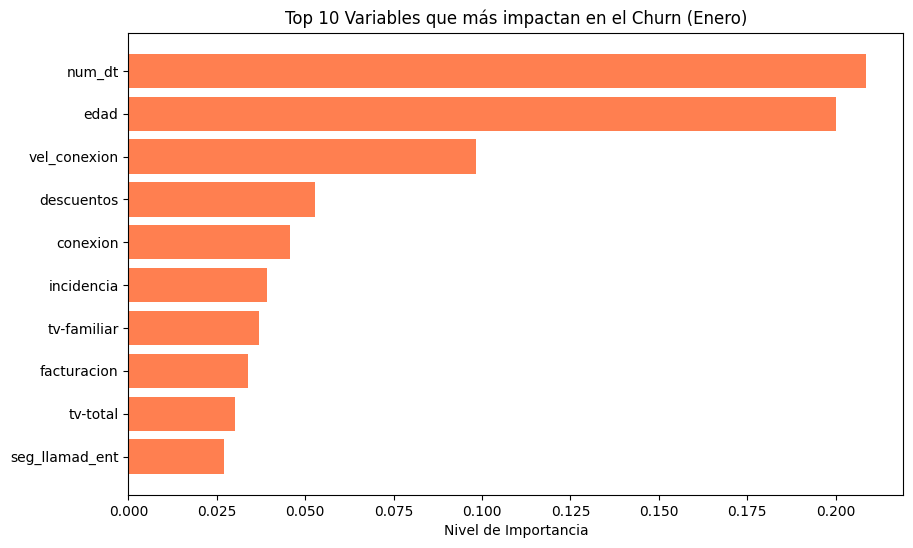

In [89]:
# Accedemos al mejor pipeline y extraemos específicamente el paso del RandomForest ('rf')
  # from matplotlib import pyplot as plt
modelo_rf_final = grid_object.best_estimator_.named_steps['rf']
importancias = modelo_rf_final.feature_importances_

# Creamos el DataFrame para visualizar
df_importancias = pd.DataFrame({
    'Variable': X_train.columns,
    'Importancia': importancias
}).sort_values(by='Importancia', ascending=False).head(10)

# Gráfico del Top 10
plt.figure(figsize=(10, 6))
plt.barh(df_importancias['Variable'][::-1], df_importancias['Importancia'][::-1], color='coral')
plt.title('Top 10 Variables que más impactan en el Churn (Enero)')
plt.xlabel('Nivel de Importancia')
plt.show()

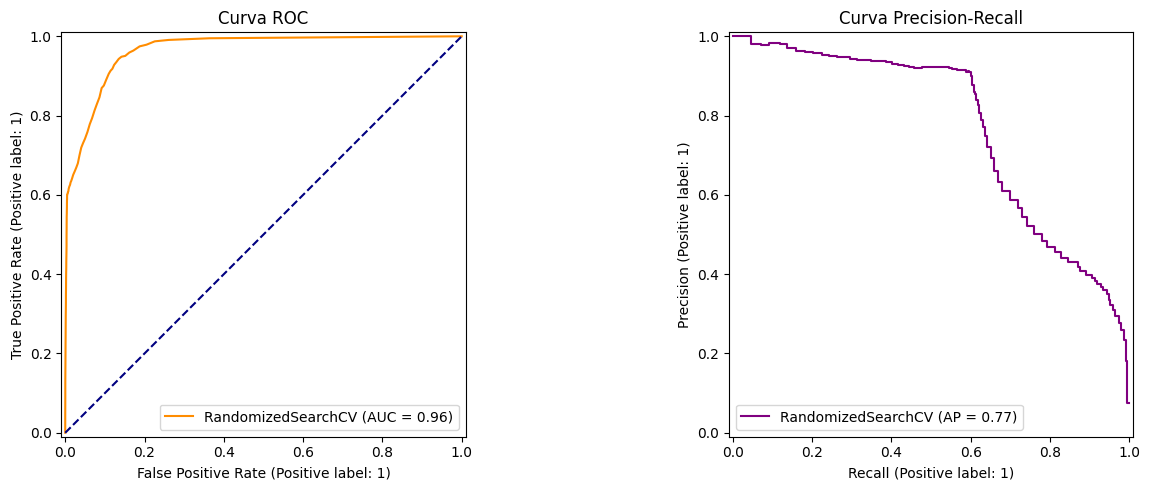

In [90]:
# Curva ROC
  # from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

RocCurveDisplay.from_estimator(grid_object, X_test, y_test, ax=ax[0], color='darkorange')
PrecisionRecallDisplay.from_estimator(grid_object, X_test, y_test, ax=ax[1], color='purple')

ax[0].plot([0, 1], [0, 1], color='navy', linestyle='--')
ax[0].set_title('Curva ROC')
ax[1].set_title('Curva Precision-Recall')

plt.tight_layout()
plt.show()

# **CREAMOS LOS ENTREGABLES**

In [91]:
  # import pickle

pkl_filename = "modelo_churn_rf.pkl"

with open(pkl_filename, 'wb') as file:
    pickle.dump(grid_object.best_estimator_, file)